# 03: Fine-pruning defense against the BadNets backdoor

**Question:** can the backdoor in `backdoored_cnn_10pct.pt` (notebook 02, 99.00% clean accuracy, 100% ASR) be removed without retraining from scratch?

**Defender assumptions**
- Has the trained model and 5,000 clean, correctly labeled training images.
- Does not know the trigger, the target class, or which training samples were poisoned.

**Method** (Liu et al., *Fine-Pruning*, 2018)
1. Run clean images through the model and record the mean activation of each of the 64 channels in the last conv layer (`conv2`).
2. Prune the channels that are least active on clean data. The idea is that backdoor behavior often sits in neurons that clean inputs rarely use.
3. Fine-tune the pruned model briefly on the clean set to recover accuracy.

Pruning alone, fine-tuning alone, and the combination are all measured so the contribution of each step is visible.

## 1. Setup

In [1]:
import copy
import csv
import random
from pathlib import Path

import torch
import torch.nn.utils.prune as prune
from torch.utils.data import DataLoader, Dataset, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from lab_utils import SmallCNN, train_one_epoch, evaluate, device

SEED = 42
ROOT = Path("..").resolve()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"

TARGET_LABEL = 0
DEFENDER_SIZE = 5000
FT_EPOCHS = 3
FT_LR = 1e-3

print("Device:", device)

Device: cuda


## 2. Data

Same trigger as notebook 02. All loaders use `num_workers=0` (classes defined in a notebook cannot be sent to worker processes on Python 3.14).

The defender's clean set is a random 5,000-image subset of the MNIST training set, taken from the original clean images.

In [2]:
transform = transforms.ToTensor()
train_set = datasets.MNIST(root=DATA_DIR, train=True,  download=True, transform=transform)
test_set  = datasets.MNIST(root=DATA_DIR, train=False, download=True, transform=transform)

def add_trigger(img):
    img = img.clone()
    img[:, -4:-1, -4:-1] = 1.0
    return img

class TriggeredSet(Dataset):
    """Non-target images with the trigger added, labeled as the target class."""
    def __init__(self, base, target_label):
        self.base = base
        self.target_label = target_label
        labels = [base[i][1] for i in range(len(base))] if isinstance(base, Subset) else base.targets.tolist()
        self.idx = [i for i, y in enumerate(labels) if y != target_label]

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, j):
        img, _ = self.base[self.idx[j]]
        return add_trigger(img), self.target_label

defender_idx = random.Random(SEED).sample(range(len(train_set)), DEFENDER_SIZE)
defender_set = Subset(train_set, defender_idx)

defender_loader       = DataLoader(defender_set, batch_size=128, shuffle=True,  num_workers=0)
defender_eval_loader  = DataLoader(defender_set, batch_size=1000, shuffle=False, num_workers=0)
clean_test_loader     = DataLoader(test_set, batch_size=1000, shuffle=False, num_workers=0)
triggered_test_loader = DataLoader(TriggeredSet(test_set, TARGET_LABEL), batch_size=1000, shuffle=False, num_workers=0)

print("Defender clean set:", len(defender_set))
print("Triggered test set:", len(triggered_test_loader.dataset))

Defender clean set: 5000
Triggered test set: 9020


## 3. Load the backdoored model and confirm the attack

In [3]:
backdoored = SmallCNN().to(device)
backdoored.load_state_dict(torch.load(RESULTS_DIR / "backdoored_cnn_10pct.pt", map_location=device))

base_clean = evaluate(backdoored, clean_test_loader)
base_asr = evaluate(backdoored, triggered_test_loader)
print(f"Backdoored model | clean acc {base_clean:.2%} | ASR {base_asr:.2%}")

Backdoored model | clean acc 99.00% | ASR 100.00%


## 4. Channel activations on clean data

A forward hook records the output of `conv2` (after ReLU), averaged over batch and spatial positions, giving one number per channel.

In [4]:
@torch.no_grad()
def channel_activations(model, loader):
    model.eval()
    batch_means = []

    def hook(module, inputs, output):
        batch_means.append(torch.relu(output).mean(dim=(0, 2, 3)))

    handle = model.conv2.register_forward_hook(hook)
    for x, _ in loader:
        model(x.to(device))
    handle.remove()
    return torch.stack(batch_means).mean(dim=0).cpu()

clean_act = channel_activations(backdoored, defender_eval_loader)
prune_order = torch.argsort(clean_act)          # least active channel first

print("Least active channels:", prune_order[:10].tolist())
print("Their mean activations:", [round(v, 4) for v in clean_act[prune_order[:10]].tolist()])
print("Dormant channels (activation < 0.01):", int((clean_act < 0.01).sum()))

Least active channels: [37, 41, 5, 6, 45, 56, 23, 46, 18, 43]
Their mean activations: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0259, 0.0279, 0.0288]
Dormant channels (activation < 0.01): 7


## 5. Diagnostic: which channels respond to the trigger?

The defender would not normally have triggered images. This check uses them only to see whether the backdoor really sits in the channels that pruning removes first.

Channels most excited by the trigger: [59, 0, 7, 39, 14]
Their position in the pruning order (0 = pruned first): {59: 60, 0: 63, 7: 59, 39: 52, 14: 53}


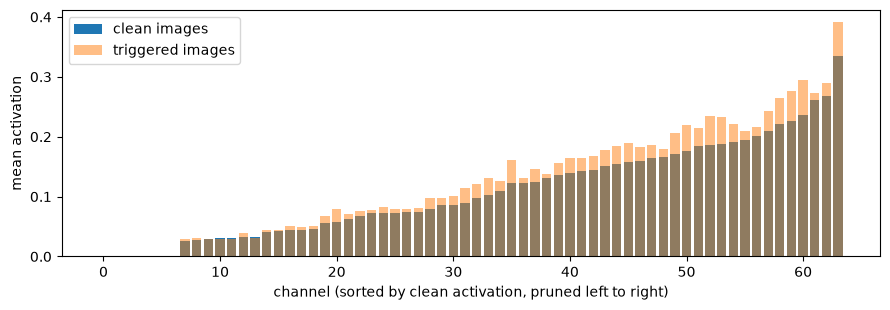

In [5]:
triggered_defender_loader = DataLoader(TriggeredSet(defender_set, TARGET_LABEL), batch_size=1000, shuffle=False, num_workers=0)
trig_act = channel_activations(backdoored, triggered_defender_loader)
gain = trig_act - clean_act

top_trigger = torch.argsort(gain, descending=True)[:5]
rank_in_prune_order = {c: (prune_order == c).nonzero().item() for c in top_trigger.tolist()}

print("Channels most excited by the trigger:", top_trigger.tolist())
print("Their position in the pruning order (0 = pruned first):", rank_in_prune_order)

order = prune_order.tolist()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(range(64), clean_act[order], label="clean images")
ax.bar(range(64), trig_act[order], alpha=0.5, label="triggered images")
ax.set_xlabel("channel (sorted by clean activation, pruned left to right)")
ax.set_ylabel("mean activation")
ax.legend(); plt.tight_layout()
plt.savefig(RESULTS_DIR / "defense_channel_activations.png", dpi=150)
plt.show()

## 6. Pruning and fine-tuning functions

Pruning uses `torch.nn.utils.prune.custom_from_mask`, which zeroes the chosen output channels of `conv2` (weights and bias) and keeps them at zero during fine-tuning.

In [6]:
def prune_channels(model, n_prune):
    pruned = copy.deepcopy(model)
    channels = prune_order[:n_prune]
    w_mask = torch.ones_like(pruned.conv2.weight)
    b_mask = torch.ones_like(pruned.conv2.bias)
    w_mask[channels] = 0
    b_mask[channels] = 0
    prune.custom_from_mask(pruned.conv2, "weight", w_mask)
    prune.custom_from_mask(pruned.conv2, "bias", b_mask)
    return pruned

def fine_tune(model):
    torch.manual_seed(SEED)
    optimizer = torch.optim.Adam(model.parameters(), lr=FT_LR)
    for _ in range(FT_EPOCHS):
        train_one_epoch(model, defender_loader, optimizer)
    return model

## 7. Pruning only

In [7]:
PRUNE_FRACTIONS = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
results = []

for frac in PRUNE_FRACTIONS:
    n = int(round(frac * 64))
    m = prune_channels(backdoored, n)
    clean_acc, asr = evaluate(m, clean_test_loader), evaluate(m, triggered_test_loader)
    results.append({"method": "prune", "prune_frac": frac, "channels_pruned": n, "clean_acc": clean_acc, "asr": asr})
    print(f"prune {frac:>4.0%} ({n:>2} ch) | clean acc {clean_acc:.2%} | ASR {asr:.2%}")

prune   0% ( 0 ch) | clean acc 99.00% | ASR 100.00%
prune  10% ( 6 ch) | clean acc 99.00% | ASR 100.00%
prune  20% (13 ch) | clean acc 98.94% | ASR 100.00%
prune  30% (19 ch) | clean acc 98.91% | ASR 100.00%
prune  40% (26 ch) | clean acc 98.78% | ASR 99.93%
prune  50% (32 ch) | clean acc 98.38% | ASR 99.83%
prune  60% (38 ch) | clean acc 97.72% | ASR 99.35%
prune  70% (45 ch) | clean acc 97.96% | ASR 99.92%
prune  80% (51 ch) | clean acc 91.18% | ASR 92.54%
prune  90% (58 ch) | clean acc 63.78% | ASR 84.18%


## 8. Fine-pruning (prune, then fine-tune on the defender set)

The 0% row is fine-tuning alone, without pruning. It shows how much of any improvement comes from fine-tuning rather than pruning.

In [8]:
for frac in PRUNE_FRACTIONS:
    n = int(round(frac * 64))
    m = fine_tune(prune_channels(backdoored, n))
    clean_acc, asr = evaluate(m, clean_test_loader), evaluate(m, triggered_test_loader)
    results.append({"method": "fine-prune", "prune_frac": frac, "channels_pruned": n, "clean_acc": clean_acc, "asr": asr})
    print(f"fine-prune {frac:>4.0%} ({n:>2} ch) | clean acc {clean_acc:.2%} | ASR {asr:.2%}")

fine-prune   0% ( 0 ch) | clean acc 98.93% | ASR 99.99%
fine-prune  10% ( 6 ch) | clean acc 98.93% | ASR 99.99%
fine-prune  20% (13 ch) | clean acc 98.96% | ASR 99.99%
fine-prune  30% (19 ch) | clean acc 98.98% | ASR 99.99%
fine-prune  40% (26 ch) | clean acc 98.83% | ASR 99.99%
fine-prune  50% (32 ch) | clean acc 98.88% | ASR 99.98%
fine-prune  60% (38 ch) | clean acc 98.93% | ASR 99.83%
fine-prune  70% (45 ch) | clean acc 98.91% | ASR 99.05%
fine-prune  80% (51 ch) | clean acc 98.67% | ASR 84.66%
fine-prune  90% (58 ch) | clean acc 97.90% | ASR 50.06%


## 9. Save results

In [9]:
with open(RESULTS_DIR / "defense_results.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["method", "prune_frac", "channels_pruned", "clean_acc", "asr"])
    writer.writeheader()
    writer.writerows(results)

print(f"{'method':>11} {'pruned':>7} {'clean acc':>10} {'ASR':>8}")
for r in results:
    print(f"{r['method']:>11} {r['prune_frac']:>7.0%} {r['clean_acc']:>10.2%} {r['asr']:>8.2%}")

     method  pruned  clean acc      ASR
      prune      0%     99.00%  100.00%
      prune     10%     99.00%  100.00%
      prune     20%     98.94%  100.00%
      prune     30%     98.91%  100.00%
      prune     40%     98.78%   99.93%
      prune     50%     98.38%   99.83%
      prune     60%     97.72%   99.35%
      prune     70%     97.96%   99.92%
      prune     80%     91.18%   92.54%
      prune     90%     63.78%   84.18%
 fine-prune      0%     98.93%   99.99%
 fine-prune     10%     98.93%   99.99%
 fine-prune     20%     98.96%   99.99%
 fine-prune     30%     98.98%   99.99%
 fine-prune     40%     98.83%   99.99%
 fine-prune     50%     98.88%   99.98%
 fine-prune     60%     98.93%   99.83%
 fine-prune     70%     98.91%   99.05%
 fine-prune     80%     98.67%   84.66%
 fine-prune     90%     97.90%   50.06%


## 10. Plot

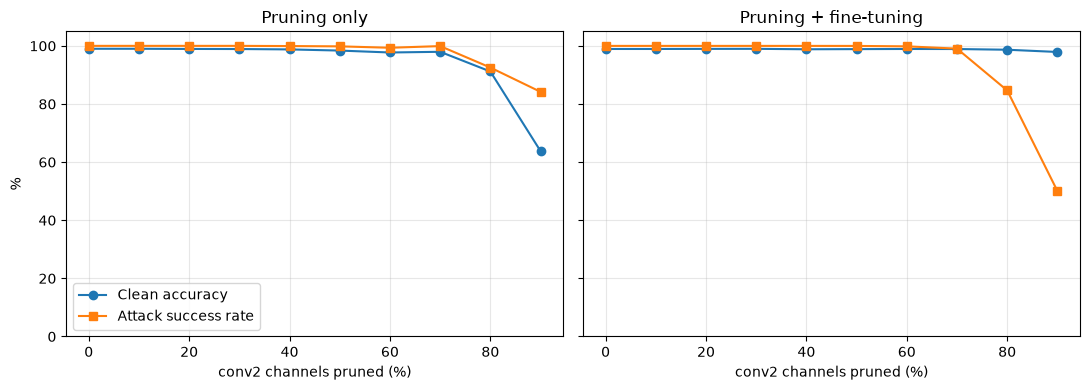

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, method, title in [(axes[0], "prune", "Pruning only"), (axes[1], "fine-prune", "Pruning + fine-tuning")]:
    rows = [r for r in results if r["method"] == method]
    x = [r["prune_frac"] * 100 for r in rows]
    ax.plot(x, [r["clean_acc"] * 100 for r in rows], marker="o", label="Clean accuracy")
    ax.plot(x, [r["asr"] * 100 for r in rows], marker="s", label="Attack success rate")
    ax.set_title(title); ax.set_xlabel("conv2 channels pruned (%)")
    ax.set_ylim(0, 105); ax.grid(alpha=0.3)
axes[0].set_ylabel("%"); axes[0].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "defense_plot.png", dpi=150)
plt.show()

## Findings

**Fine-pruning did not remove this backdoor without a large loss in clean accuracy.**

| conv2 channels pruned | Pruning only: clean / ASR | Fine-pruning: clean / ASR |
|---|---|---|
| 0% | 99.00% / 100.00% | 98.93% / 99.99% |
| 50% | 98.38% / 99.83% | 98.88% / 99.98% |
| 70% | 97.96% / 99.92% | 98.91% / 99.05% |
| 80% | 91.18% / 92.54% | 98.67% / 84.66% |
| 90% | 63.78% / 84.18% | 97.90% / 50.06% |

- **Pruning alone has almost no effect on the backdoor.** ASR stays above 99% until 70% of channels are removed. At 90% the model is mostly broken (63.78% clean accuracy) and the trigger still works on 84% of images.
- **Fine-tuning alone does nothing.** Three epochs on 5,000 clean images left ASR at 99.99%.
- **The combination works only partly.** The best result (90% pruned, then fine-tuned) cuts ASR to 50.06% while keeping 97.90% clean accuracy. Half of triggered inputs still go to the attacker's class, which would not count as a successful defense.
- **The reason is visible in the activation diagnostic (section 5).** Fine-pruning assumes the backdoor sits in channels that are quiet on clean data. Here it is the opposite: the five channels most excited by the trigger rank 52, 53, 59, 60 and 63 out of 64 in the pruning order, i.e. they are among the *most* active on clean digits and are pruned last. The 7 completely dormant channels have nothing to do with the trigger. A bright, high-contrast patch is the kind of feature that ordinary stroke and edge detectors already respond to, so the model reuses those channels for the backdoor instead of dedicating separate ones.

**Limitations**
- Only `conv2` was pruned. Part of the backdoor may be stored in the fully connected layers.
- One seed, one fine-tuning setting (3 epochs, lr 1e-3), and only the 10% model was tested.
- The trigger diagnostic uses triggered images, which a real defender would not have.

**Next steps**
- Repeat on the 1% model, where the backdoor may be encoded differently.
- Prune `fc1` as well, and try longer fine-tuning.
- Compare with defenses that do not rely on dormant neurons, such as activation clustering or spectral signatures, which inspect the training data instead of the model.